In [2]:
import pandas as pd 

df = pd.read_csv("Reviews.csv")

print(df.head())

   Id   ProductId          UserId                      ProfileName  \
0   1  B001E4KFG0  A3SGXH7AUHU8GW                       delmartian   
1   2  B00813GRG4  A1D87F6ZCVE5NK                           dll pa   
2   3  B000LQOCH0   ABXLMWJIXXAIN  Natalia Corres "Natalia Corres"   
3   4  B000UA0QIQ  A395BORC6FGVXV                             Karl   
4   5  B006K2ZZ7K  A1UQRSCLF8GW1T    Michael D. Bigham "M. Wassir"   

   HelpfulnessNumerator  HelpfulnessDenominator  Score        Time  \
0                     1                       1      5  1303862400   
1                     0                       0      1  1346976000   
2                     1                       1      4  1219017600   
3                     3                       3      2  1307923200   
4                     0                       0      5  1350777600   

                 Summary                                               Text  
0  Good Quality Dog Food  I have bought several of the Vitality canned d...  
1 

In [11]:
print(df['Id'].count())
print(df["ProductId"].nunique())
# print(df["UserId"].count())
print(df["UserId"].nunique())

568454
74258
256059


In [ ]:
print(df['ProductId'].value_counts())
print(df['ProductId'].value_counts().idxmax())

ProductId
B007JFMH8M    913
B002QWHJOU    632
B0026RQTGE    632
B002QWP89S    632
B002QWP8H0    632
             ... 
B000M6CTGK      1
B000MAST88      1
B0064KU9HO      1
B0001WYNFA      1
B000KOUOHU      1
Name: count, Length: 74258, dtype: int64
B007JFMH8M


In [15]:
print(df['UserId'].value_counts())
print(df['UserId'].value_counts().idxmax())

UserId
A3OXHLG6DIBRW8    448
A1YUL9PCJR3JTY    421
AY12DBB0U420B     389
A281NPSIMI1C2R    365
A1Z54EM24Y40LL    256
                 ... 
AEW1UWTI3MCVN       1
ALMANY3CKWVH7       1
A1UJMVE0LCOI45      1
A6RFVZFCCPPAB       1
A24LQ099X444C1      1
Name: count, Length: 256059, dtype: int64
A3OXHLG6DIBRW8


In [16]:
print(df.loc[df['UserId'] == 'A3OXHLG6DIBRW8', 'ProfileName'])

369       C. F. Hill "CFH"
813       C. F. Hill "CFH"
3306      C. F. Hill "CFH"
3416      C. F. Hill "CFH"
3926      C. F. Hill "CFH"
                ...       
562279    C. F. Hill "CFH"
563973    C. F. Hill "CFH"
564414    C. F. Hill "CFH"
567686    C. F. Hill "CFH"
567796    C. F. Hill "CFH"
Name: ProfileName, Length: 448, dtype: object


In [17]:
print(df['ProductId'].value_counts().head(5))

ProductId
B007JFMH8M    913
B002QWHJOU    632
B0026RQTGE    632
B002QWP89S    632
B002QWP8H0    632
Name: count, dtype: int64


In [18]:
print(df['UserId'].value_counts().head(5))

UserId
A3OXHLG6DIBRW8    448
A1YUL9PCJR3JTY    421
AY12DBB0U420B     389
A281NPSIMI1C2R    365
A1Z54EM24Y40LL    256
Name: count, dtype: int64


In [19]:
top_5_users = (
    df.groupby('UserId')
      .agg(
          ReviewCount=('Id', 'count'),
          ProfileName=('ProfileName', 'first')
      )
      .sort_values('ReviewCount', ascending=False)
      .head(5)
)

print(top_5_users)

                ReviewCount                             ProfileName
UserId                                                             
A3OXHLG6DIBRW8          448                        C. F. Hill "CFH"
A1YUL9PCJR3JTY          421         O. Brown "Ms. O. Khannah-Brown"
AY12DBB0U420B           389                           Gary Peterson
A281NPSIMI1C2R          365  Rebecca of Amazon "The Rebecca Review"
A1Z54EM24Y40LL          256                                      c2


In [20]:
top_3_helpful = (
    df.groupby(['UserId', 'ProfileName'])
      .agg(
          TotalHelpful=('HelpfulnessNumerator', 'sum'),
          TotalVotes=('HelpfulnessDenominator', 'sum'),
          ReviewCount=('Id', 'count')
      )
      .sort_values('TotalHelpful', ascending=False)
      .head(3)
)

print(top_3_helpful)

                                               TotalHelpful  TotalVotes  \
UserId         ProfileName                                                
A1B4MIXYVIKMU2 D. Truong "Duke of New Mexico"          5594        5629   
A10PV6AP8SXEDI J. Goldman                              4720        4770   
A32WS1SQTDYYO  G. Roberti "Lube Man"                   3648        3712   

                                               ReviewCount  
UserId         ProfileName                                  
A1B4MIXYVIKMU2 D. Truong "Duke of New Mexico"           23  
A10PV6AP8SXEDI J. Goldman                               10  
A32WS1SQTDYYO  G. Roberti "Lube Man"                    13  


In [22]:
positive_reviews = df[df['Score'] == 5]

print(positive_reviews['ProductId'].value_counts().head(1))

ProductId
B007JFMH8M    624
Name: count, dtype: int64


In [23]:
positive_reviews = df[df['Score'] == 5]

print(positive_reviews['ProductId'].value_counts().head(3))

ProductId
B007JFMH8M    624
B003B3OOPA    517
B000NMJWZO    502
Name: count, dtype: int64


In [3]:
negative_reviews = df[df['Score'] == 1]

top_3_negative = (
    negative_reviews.groupby(['UserId', 'ProfileName'])
    .size()
    .sort_values(ascending=False)
    .head(3)
)

print(top_3_negative)

UserId          ProfileName      
A3TVZM3ZIXG8YW  christopher hayes    199
AKZKG2Z7CNV27   BreezyPaige           67
AMQ1MEG334SAP   Bigmac                47
dtype: int64


In [4]:
import pandas as pd

user_id = 'A3OXHLG6DIBRW8'

user_purchases = df[df['UserId'] == user_id].copy()

# Convert Unix timestamp to readable datetime
user_purchases['Date'] = pd.to_datetime(
    user_purchases['Time'], unit='s'
)

# Sort by date
user_purchases = user_purchases.sort_values('Date')

# Display relevant columns
print(user_purchases[
    ['UserId', 'ProductId', 'ProfileName', 'Date', 'Score', 'Summary']
])

                UserId   ProductId       ProfileName       Date  Score  \
17732   A3OXHLG6DIBRW8  B000Z978SS  C. F. Hill "CFH" 2008-10-17      4   
53534   A3OXHLG6DIBRW8  B000UPALKO  C. F. Hill "CFH" 2008-10-28      5   
267431  A3OXHLG6DIBRW8  B000UPALJ0  C. F. Hill "CFH" 2008-10-28      5   
241519  A3OXHLG6DIBRW8  B001G8W7YC  C. F. Hill "CFH" 2008-11-01      5   
390638  A3OXHLG6DIBRW8  B0008JF9FY  C. F. Hill "CFH" 2008-11-06      5   
...                ...         ...               ...        ...    ...   
302032  A3OXHLG6DIBRW8  B0048CHI9M  C. F. Hill "CFH" 2012-09-29      5   
76811   A3OXHLG6DIBRW8  B007SHZ7SS  C. F. Hill "CFH" 2012-10-14      5   
226476  A3OXHLG6DIBRW8  B00016LA7K  C. F. Hill "CFH" 2012-10-15      5   
389618  A3OXHLG6DIBRW8  B004N5KUO4  C. F. Hill "CFH" 2012-10-21      5   
417052  A3OXHLG6DIBRW8  B007R0QWO4  C. F. Hill "CFH" 2012-10-24      5   

                                                  Summary  
17732   Really Good Sugar Substitute - Highly Recom

                UserId   ProductId       ProfileName       Date  Score  \
17732   A3OXHLG6DIBRW8  B000Z978SS  C. F. Hill "CFH" 2008-10-17      4   
53534   A3OXHLG6DIBRW8  B000UPALKO  C. F. Hill "CFH" 2008-10-28      5   
267431  A3OXHLG6DIBRW8  B000UPALJ0  C. F. Hill "CFH" 2008-10-28      5   
241519  A3OXHLG6DIBRW8  B001G8W7YC  C. F. Hill "CFH" 2008-11-01      5   
390638  A3OXHLG6DIBRW8  B0008JF9FY  C. F. Hill "CFH" 2008-11-06      5   
...                ...         ...               ...        ...    ...   
302032  A3OXHLG6DIBRW8  B0048CHI9M  C. F. Hill "CFH" 2012-09-29      5   
76811   A3OXHLG6DIBRW8  B007SHZ7SS  C. F. Hill "CFH" 2012-10-14      5   
226476  A3OXHLG6DIBRW8  B00016LA7K  C. F. Hill "CFH" 2012-10-15      5   
389618  A3OXHLG6DIBRW8  B004N5KUO4  C. F. Hill "CFH" 2012-10-21      5   
417052  A3OXHLG6DIBRW8  B007R0QWO4  C. F. Hill "CFH" 2012-10-24      5   

                                                  Summary  
17732   Really Good Sugar Substitute - Highly Recom

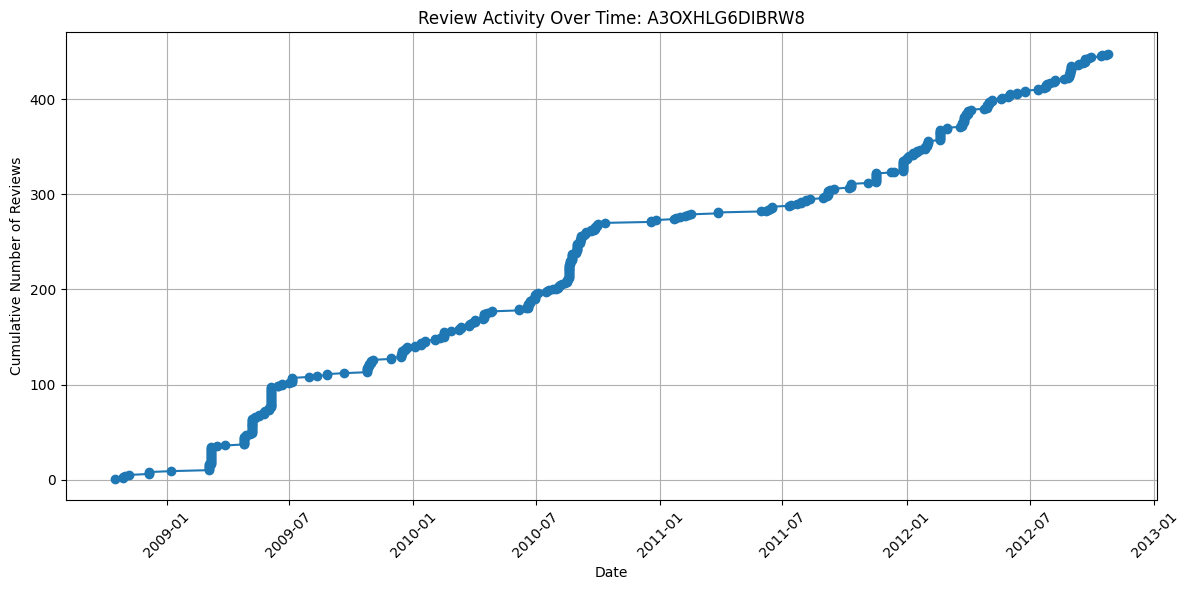

In [5]:
import pandas as pd
import matplotlib.pyplot as plt

user_id = 'A3OXHLG6DIBRW8'

# Filter the user's reviews
user_purchases = df[df['UserId'] == user_id].copy()

# Convert Unix timestamp to datetime
user_purchases['Date'] = pd.to_datetime(
    user_purchases['Time'], unit='s'
)

# Sort by date
user_purchases = user_purchases.sort_values('Date')

# Display the reviews
print(user_purchases[
    ['UserId', 'ProductId', 'ProfileName',
     'Date', 'Score', 'Summary']
])

# Plot review activity over time
plt.figure(figsize=(12, 6))
plt.plot(
    user_purchases['Date'],
    range(1, len(user_purchases) + 1),
    marker='o'
)

plt.title(f'Review Activity Over Time: {user_id}')
plt.xlabel('Date')
plt.ylabel('Cumulative Number of Reviews')
plt.xticks(rotation=45)
plt.grid(True)
plt.tight_layout()
plt.show()

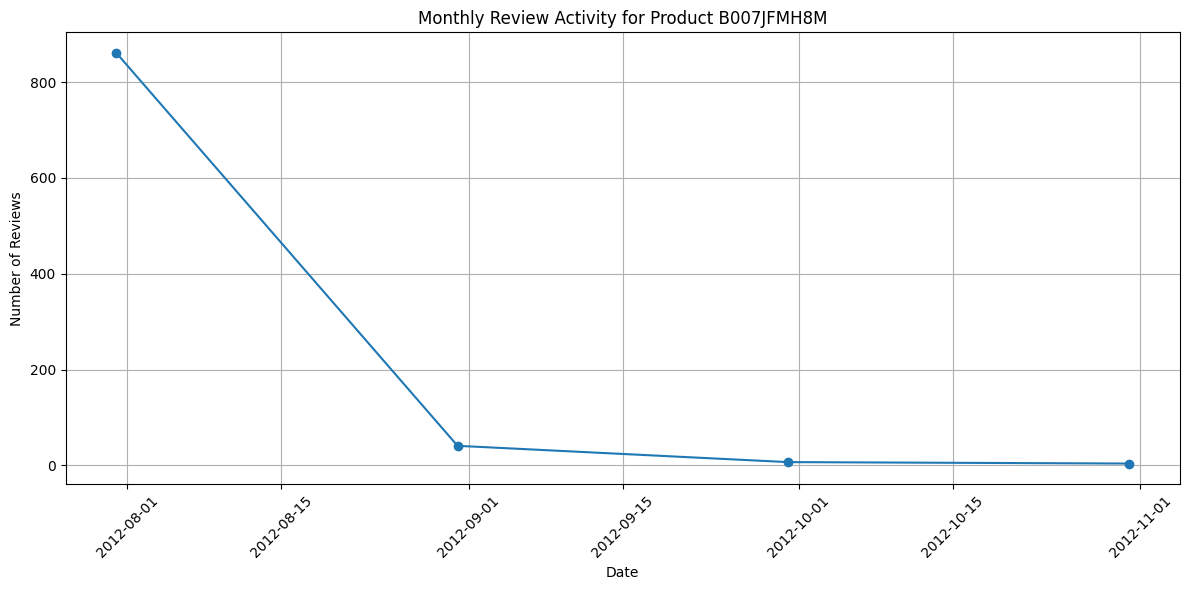

In [10]:
import pandas as pd
import matplotlib.pyplot as plt

product_id = 'B007JFMH8M'

# Filter reviews for the product
product_reviews = df[df['ProductId'] == product_id].copy()

# Convert Unix timestamps to dates
product_reviews['Date'] = pd.to_datetime(
    product_reviews['Time'], unit='s'
)

# Count reviews per month
monthly_reviews = (
    product_reviews.set_index('Date')
    .resample('ME')
    .size()
)

# Plot review activity
plt.figure(figsize=(12, 6))

plt.plot(
    monthly_reviews.index,
    monthly_reviews.values,
    marker='o'
)

plt.title(f'Monthly Review Activity for Product {product_id}')
plt.xlabel('Date')
plt.ylabel('Number of Reviews')
plt.xticks(rotation=45)
plt.grid(True)
plt.tight_layout()
plt.show()

In [7]:
import pandas as pd
import matplotlib.pyplot as plt

# Convert Unix timestamps to dates
df['Date'] = pd.to_datetime(df['Time'], unit='s')

# Count reviews per product per month
monthly = (
    df.groupby([
        'ProductId',
        pd.Grouper(key='Date', freq='ME')
    ])
    .size()
    .rename('Reviews')
    .reset_index()
)

results = []

for product_id, group in monthly.groupby('ProductId'):
    group = group.sort_values('Date')

    # Skip products with too little history
    if len(group) < 2:
        continue

    midpoint = len(group) // 2

    first_half = group.iloc[:midpoint]['Reviews'].sum()
    second_half = group.iloc[midpoint:]['Reviews'].sum()

    growth = second_half - first_half
    growth_pct = (
        (second_half - first_half) / first_half * 100
        if first_half > 0 else None
    )

    results.append({
        'ProductId': product_id,
        'FirstHalfReviews': first_half,
        'SecondHalfReviews': second_half,
        'Growth': growth,
        'GrowthPercent': growth_pct
    })

growth_df = pd.DataFrame(results)

# Rank by absolute increase in reviews
top_products = growth_df.sort_values(
    'Growth', ascending=False
).head(5)

print(top_products)

        ProductId  FirstHalfReviews  SecondHalfReviews  Growth  GrowthPercent
30023  B003B3OOPA                51                572     521    1021.568627
27137  B002LANN56                 5                459     454    9080.000000
27675  B002QWHJOU               123                509     386     313.821138
27681  B002QWP8H0               123                509     386     313.821138
27680  B002QWP89S               123                509     386     313.821138


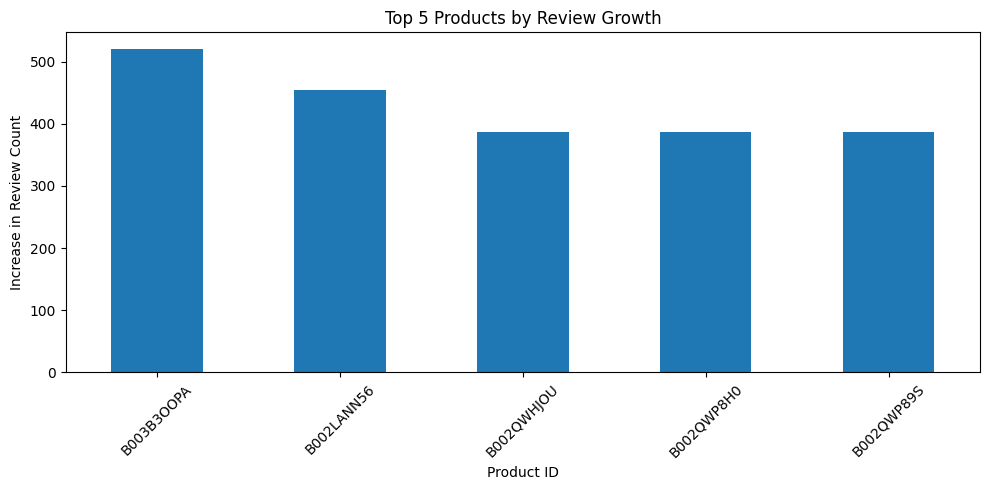

In [8]:
top_products.plot(
    x='ProductId',
    y='Growth',
    kind='bar',
    legend=False,
    figsize=(10, 5)
)

plt.title('Top 5 Products by Review Growth')
plt.xlabel('Product ID')
plt.ylabel('Increase in Review Count')
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()